In [1]:
from IPython.display import Image

<div dir="rtl">  


# יציבות
<div dir="rtl">

## כאשר אנחנו עושים סימולציה סטציונרית עלינו לוודא שהמערכת יציבה. מערכת יציבה היא כזאת שקצב הגעה שלה הוא קטן מקצב שירות.
## עבור תור עם שרת יחיד מערכת יציבה צריכה לעמוד בתנאי:  

##  $$ \frac{ \lambda }{\mu} < 1 $$

<div dir="rtl">  
    
## * $\lambda$ קצב הגעה
## * $\mu$ קצב שירות

<div dir="rtl">

###     עבור תור עם k שרתים תנאי יציבות הוא: 

## $$ \frac{ \lambda }{k\mu} < 1 $$

## מה קורה במערכת שיש מספר זרמים של הגעות?

## נניח כי יש לנו את המערכת הבאה:



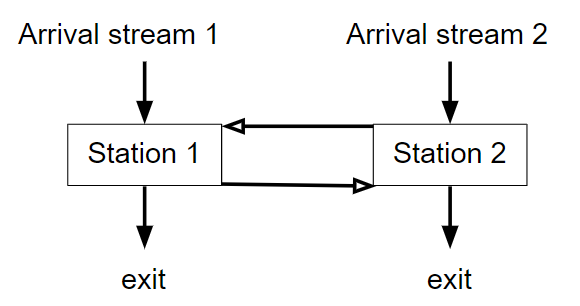

In [2]:
Image('../../Images/stability_example.png', width=820)

<div dir="rtl">

## יש לנו 2 תחנות. צרכנים שמגיעים לשירות בתחנה 1 יצטרכו לעבור בהסתברות מסוימת לתחנה 2 וגם ההיפך.  


    
##  $r_{i}$ קצב הגעה חיצוני לתחנה i 
## $\lambda_{i}$ קצב הגעה אפקטיבי לתחנה i  כלומר כמה הגיעו בפועל  
## $p_{i,j}$ ההסתברות שצרכן  שהגיע לתחנה i יעבור לתחנה j אחרי שירות   

## כדי לחשב קצבי הגעה אפטקיביים:

# $$ \lambda_i = r_i + \sum_{j \neq i}\lambda_j p_{j,i} $$

### למשל במקרה של 2 תחנות:

### $$ \lambda_1 = r_1 + \lambda_2 p_{2,1} $$

### $$ \lambda_2 = r_2 + \lambda_1 p_{1,2} $$

### למשל במקרה של 3 תחנות:

### $$ \lambda_1 = r_1 + \lambda_2 p_{2,1}+ \lambda_3 p_{3,1} $$

### $$ \lambda_2 = r_2 + \lambda_1 p_{1,2} + \lambda_3 p_{3,2} $$

### $$ \lambda_3 = r_3 + \lambda_1 p_{1,3} + \lambda_2 p_{2,3} $$

    
###    במקרה שלנו יש לנו 2 משוואות עם שני נעלמים: $\lambda_1$, $\lambda_2$

    
### אם נפתור, נקבל

### $$\lambda_2= \frac{r_2+r_1 p_{1,2}}{1-p_{2,1}*p_{1,2}}$$

### $$ \lambda_1 = r_1 + \lambda_2 p_{2,1} $$

### ניתן דוגמא: 

<div dir="rtl"> 
    
## במערכת זו - צרכן שמגיע לתחנה 1 בהסתברות 0.5 יעבור לתחנה 2 אחרי זה. 
    
    
### אמנם הקצב החיצוני לכל תחנה הוא 1 אבל בפועל (קצב אפקטיבי) הקצב של תחנה 2 הוא 1.5. 

In [3]:
r1 = 1
r2 = 1
p12 = 0.5
p21 = 0
lam2 = (r2+r1*p12)/(1-p12*p21)
lam1 = r1+lam2*p21
lam1, lam2

(1.0, 1.5)

<div dir="rtl">

## אם למשל קצב השירות  של תחנות 1 וגם 2 הוא 1.25 אזי המערכת לא תהיה יציבה כי קצב ההגעה לתחנה 2 גדול מקצב השירות. נראה איך זה נראה בסימולציה. במקרה זה ככל שזמן סימולציה גדל - זמני המתנה רק יגדלו.


<div dir="rtl">

## דוגמה: מערכת feedback loop עם משוואות תנועה

### כעת נסתכל על מערכת פתוחה עם שלוש תחנות, שבה לקוחות יכולים לחזור לתחנה שכבר היו בה.
### ההגעה החיצונית ידועה, וזמני השירות ידועים דרך קצבי השירות.
### לכן אפשר לחשב את קצבי ההגעה האפקטיביים לכל תחנה בעזרת מערכת משוואות ליניאריות.
### לאחר מכן מחשבים את הנצילות בכל תחנה ובודקים אם המערכת יציבה.

</div>


In [4]:
import sys
import importlib

sys.path.append("../../code")

import utils
importlib.reload(utils)

from utils import (
    draw_queue_network,
    feedback_loop_utilization_examples,
    plot_feedback_waiting_time_over_time,
    simulate_feedback_stability_comparison,
)


<div dir="rtl">

## מבנה ה-feedback loop

### בדוגמה הזאת יש הגעות חיצוניות אל $S_1$ ואל $S_2$.
### אחרי שירות ב-$S_1$, לקוח עובר ל-$S_2$ בהסתברות $0.6$, ובשאר המקרים עוזב את המערכת.
### אחרי שירות ב-$S_2$, לקוח יכול לחזור ל-$S_1$ בהסתברות $0.25$, לעבור ל-$S_3$ בהסתברות $0.55$, או לעזוב את המערכת.
### אחרי שירות ב-$S_3$, לקוח יכול לחזור ל-$S_1$ בהסתברות $0.2$, או לעזוב את המערכת.
### לכן יש כאן feedback loop: מסלול אפשרי הוא $S_1 \to S_2 \to S_3 \to S_1$.

</div>


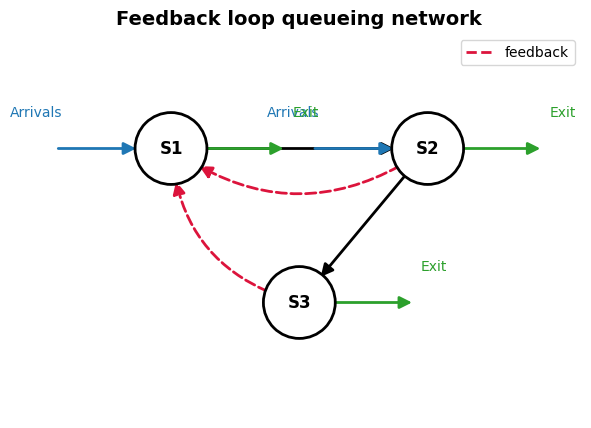

In [5]:
feedback_positions = {
    "S1": (0, 0),
    "S2": (2, 0),
    "S3": (1, -1.2),
}

feedback_edges = [
    ("S1", "S2"),
    ("S2", "S1"),
    ("S2", "S3"),
    ("S3", "S1"),
]

draw_queue_network(
    positions=feedback_positions,
    edges=feedback_edges,
    title="Feedback loop queueing network",
    entry_nodes=["S1", "S2"],
    exit_nodes=["S1", "S2", "S3"],
    feedback_edges=[("S2", "S1"), ("S3", "S1")],
    figsize=(8, 5),
)


<div dir="rtl">

## המשוואות הליניאריות

### נסמן את קצב ההגעה החיצוני לתחנה $i$ ב-$r_i$.
### נסמן את קצב ההגעה האפקטיבי לתחנה $i$ ב-$\lambda_i$.
### נסמן את הסתברות המעבר מתחנה $i$ לתחנה $j$ ב-$p_{i,j}$.
### לכל תחנה מתקיים:
### $$\lambda_i = r_i + \sum_j \lambda_j p_{j,i}$$
### בצורה מטריציונית, אם $P$ היא מטריצת המעבר בין התחנות, אז:
### $$\lambda = r + P^T\lambda$$
### לכן:
### $$(I-P^T)\lambda = r$$
### ופותרים את מערכת המשוואות כדי לקבל את $\lambda$.
### אחרי שמצאנו את קצב ההגעה האפקטיבי לכל תחנה, מחשבים נצילות:
### $$\rho_i=\frac{\lambda_i}{c_i\mu_i}$$
### כאשר $c_i$ הוא מספר השרתים בתחנה ו-$\mu_i$ הוא קצב השירות של שרת אחד בתחנה.
### עבור שרת יחיד, זה פשוט $\rho_i=\frac{\lambda_i}{\mu_i}$.
### תנאי היציבות הוא שכל הנצילויות יהיו קטנות מ-$1$.

</div>


<div dir="rtl">

## קוד מפורש לחישוב קצבי הגעה ונצילות

### בתא הבא רואים את החישוב עצמו, בלי להסתיר אותו בתוך פונקציה.
### קודם בונים את מטריצת המעבר $P$ ואת וקטור ההגעות החיצוניות $r$.
### אחר כך פותרים את מערכת המשוואות $\lambda = r + P^T\lambda$ בעזרת $\lambda=(I-P^T)^{-1}r$.
### לבסוף מחשבים לכל תחנה את הנצילות $\rho_i=\frac{\lambda_i}{c_i\mu_i}$.
### אותה מטריצת מעבר ואותן הגעות חיצוניות ישמשו גם לדוגמה היציבה וגם לדוגמה הלא יציבה.

</div>


In [6]:
import numpy as np
import pandas as pd

stations = ["S1", "S2", "S3"]

P = pd.DataFrame(
    [
        [0.00, 0.60, 0.00],
        [0.25, 0.00, 0.55],
        [0.20, 0.00, 0.00],
    ],
    index=stations,
    columns=stations,
)

r = pd.Series([0.55, 0.10, 0.00], index=stations, name="external_arrival_rate")
c = pd.Series([1, 1, 1], index=stations, name="servers")
mu_stable = pd.Series([1.20, 1.10, 0.90], index=stations, name="service_rate")
mu_unstable = pd.Series([0.70, 0.45, 0.60], index=stations, name="service_rate")

I = np.eye(len(stations))
lambda_effective = pd.Series(
    np.linalg.solve(I - P.T.to_numpy(), r.to_numpy()),
    index=stations,
    name="effective_arrival_rate",
)

explicit_stable_utilization = pd.DataFrame(
    {
        "external_arrival_rate": r,
        "effective_arrival_rate": lambda_effective,
        "service_rate": mu_stable,
        "servers": c,
        "utilization": lambda_effective / (c * mu_stable),
    }
)
explicit_stable_utilization["stable"] = explicit_stable_utilization["utilization"] < 1

explicit_unstable_utilization = pd.DataFrame(
    {
        "external_arrival_rate": r,
        "effective_arrival_rate": lambda_effective,
        "service_rate": mu_unstable,
        "servers": c,
        "utilization": lambda_effective / (c * mu_unstable),
    }
)
explicit_unstable_utilization["stable"] = explicit_unstable_utilization["utilization"] < 1

explicit_stable_utilization


,external_arrival_rate,effective_arrival_rate,service_rate,servers,utilization,stable
S1,0.55,0.747449,1.2,1,0.622874,True
S2,0.10,0.548469,1.1,1,0.498609,True
S3,0.00,0.301658,0.9,1,0.335176,True


<div dir="rtl">

## אותו חישוב עם קצבי שירות נמוכים יותר

### כעת משתמשים באותו $P$ ובאותו $r$.
### לכן קצבי ההגעה האפקטיביים $\lambda_i$ נשארים זהים.
### רק קצבי השירות $\mu_i$ משתנים, ולכן הנצילות יכולה לעבור את $1$.

</div>


In [7]:
explicit_unstable_utilization


,external_arrival_rate,effective_arrival_rate,service_rate,servers,utilization,stable
S1,0.55,0.747449,0.70,1,1.067784,False
S2,0.10,0.548469,0.45,1,1.218821,False
S3,0.00,0.301658,0.60,1,0.502764,True


In [8]:
feedback_examples = feedback_loop_utilization_examples()
feedback_examples["stable"]["routing_matrix"]


,S1,S2,S3,EXIT
S1,0.00,0.6,0.00,0.4
S2,0.25,0.0,0.55,0.2
S3,0.20,0.0,0.00,0.8


<div dir="rtl">

## דוגמה יציבה

### בדוגמה הראשונה קצבי השירות מספיק גדולים ביחס לקצבי ההגעה האפקטיביים.
### לכן כל תחנה מקבלת נצילות קטנה מ-$1$.
### במקרה כזה, מבחינת קצבי עומס, המערכת יציבה.

</div>


In [9]:
feedback_examples["stable"]["summary"]


,station,external_arrival_rate,effective_arrival_rate,service_rate,servers,utilization,stable
0,S1,0.55,0.747449,1.2,1.0,0.622874,True
1,S2,0.10,0.548469,1.1,1.0,0.498609,True
2,S3,0.00,0.301658,0.9,1.0,0.335176,True


<div dir="rtl">

## דוגמה לא יציבה

### כעת נשאיר את אותה מטריצת מעבר ואת אותם קצבי הגעה חיצוניים.
### הדבר היחיד שנשנה הוא קצבי השירות: הם יהיו קטנים יותר.
### קצבי ההגעה האפקטיביים $\lambda_i$ נשארים זהים, כי הם תלויים בהגעות החיצוניות ובניתוב.
### אבל הנצילות גדלה, כי $\mu_i$ קטן יותר.
### אם לפחות תחנה אחת מקבלת $\rho_i \ge 1$, המערכת אינה יציבה.

</div>


In [10]:
feedback_examples["unstable"]["summary"]


,station,external_arrival_rate,effective_arrival_rate,service_rate,servers,utilization,stable
0,S1,0.55,0.747449,0.70,1.0,1.067784,False
1,S2,0.10,0.548469,0.45,1.0,1.218821,False
2,S3,0.00,0.301658,0.60,1.0,0.502764,True


<div dir="rtl">

## מה חשוב לזכור

### במערכת עם feedback loop, קצב ההגעה האפקטיבי לתחנה יכול להיות גדול בהרבה מקצב ההגעה החיצוני אליה.
### הסיבה היא שלקוחות יכולים לבקר באותה תחנה יותר מפעם אחת.
### לכן לא מספיק לבדוק רק את ההגעות החיצוניות.
### צריך לפתור את משוואות התנועה, לקבל את $\lambda_i$ האפקטיביים, ורק אז לבדוק את הנצילות $\rho_i$ בכל תחנה.

<div dir="rtl">



### הדרך הזאת היא היעילה ביותר לבדוק יציבות מה שנחוץ למערכת סטציונרית. 

### אבל ניתן לבדוק זאת אפמירית גם ע"י סימולציה.

### למה שנרצה לבדוק גם ע"י סימולציה אםיש לנו שיטה יעילה ואמינה?

### 1. וידוא תוצאות. למקרה שעשינו טעות.
### 2. לפעמים המערכת תורים שלנו קצת יותר מסורבלת - שרתים יוצאים לחופשות, יש ניתוב מורכב של צרכנים ועוד. במקרה כזה לא נוכל להשתמש בשיטה הזאת.

## אז איך נבדוק יציבות?

### מה זה אומר שזה לא יציב בעצם?

### התור כל הזמן גדל ותופח. מבחינה מתמטית במצב יציב תוחלת זמן המתנה נשארת קבועה בזמן ואילו במערכת לא יציבה היא גדלה עם הזמן. 


<div dir="rtl">

## בדיקת יציבות בעזרת סימולציה

### עד עכשיו בדקנו יציבות על ידי חישוב נצילות מתוך משוואות התנועה.
### עכשיו נבדוק את אותה אינטואיציה בעזרת סימולציה.
### נריץ פעם אחת את המערכת היציבה ופעם אחת את המערכת הלא יציבה.
### בכל ריצה נמדוד זמני המתנה, ונחשב את ממוצע זמן ההמתנה המצטבר עד זמן $t$.
### אם המערכת יציבה, הממוצע המצטבר אמור להתקרב לרמה פחות או יותר קבועה.
### אם המערכת לא יציבה, התורים הולכים וגדלים, ולכן גם זמני ההמתנה צפויים להמשיך לעלות.

</div>


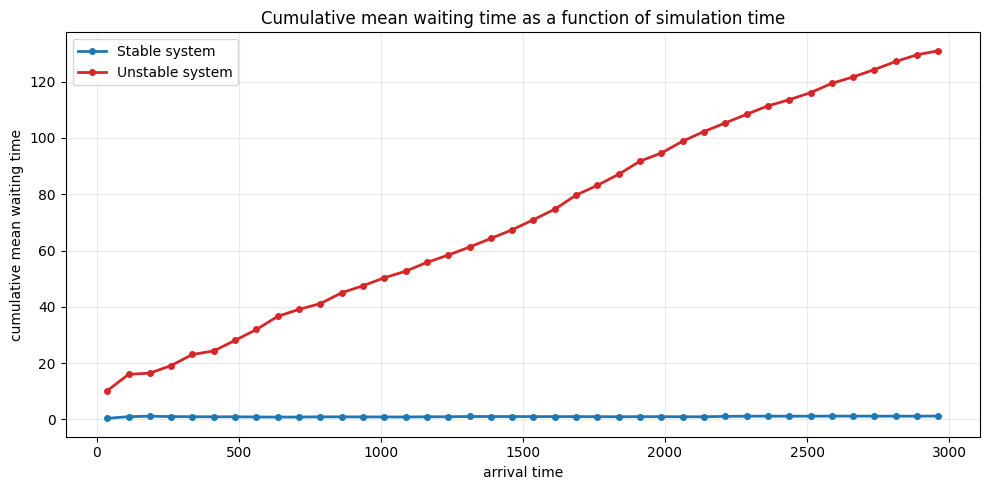

In [11]:
feedback_stability_comparison = simulate_feedback_stability_comparison(
    horizon=3_000,
    seed=2027,
    num_bins=40,
)

plot_feedback_waiting_time_over_time(feedback_stability_comparison)


<div dir="rtl">

## קריאת הגרף

### הציר האופקי הוא זמן ההגעה למערכת או לאחת התחנות.
### הציר האנכי הוא ממוצע זמן ההמתנה המצטבר עד אותו זמן.
### במערכת היציבה העקומה אמורה להתייצב סביב רמת המתנה אופיינית.
### במערכת הלא יציבה העקומה אמורה לטפס, כי עומס של לפחות תחנה אחת גדול מ-$1$.
### שימו לב שזהו אומדן סימולטיבי: יש רעש אקראי, אבל המגמה היא הדבר החשוב.

</div>
